In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
wine = load_wine()
X = wine['data']
Y = wine['target']

In [23]:
#from sklearn.datasets import load_breast_cancer
#cancer = load_breast_cancer()
#X = cancer['data']
#Y = cancer['target']

In [24]:
from sklearn import tree,neighbors
from sklearn.model_selection import train_test_split

In [25]:
print('Доля, которую занимает тестовая выборка от общего размера набора данных:')
test_data=float(input())
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=test_data)

Доля, которую занимает тестовая выборка от общего размера набора данных:
0.4


In [26]:
model=neighbors.KNeighborsClassifier()
model.fit(X,Y)
model.score(X,Y)
#precision - доля правильных положительных результатов среди всех положительных
#recall - доля правильных положительных среди всех правильных
#f-score - среднее гармоническое значение между precision и recall
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
predictions=model.predict(x_test)
print('Показатели точности классификации данного набора:')
accuracy=accuracy_score(y_test,predictions)
print(f'Accuracy: {accuracy}')

Показатели точности классификации данного набора:
Accuracy: 0.8055555555555556


In [27]:
micro_precision = precision_score(predictions, y_test, average='micro')
micro_f1=f1_score(y_test, predictions, average='micro')
micro_recall=recall_score(y_test, predictions, average='micro')
print(f'Micro-averaged precision, recall and F1 score: {micro_precision}, {micro_recall}, {micro_f1}')

Micro-averaged precision, recall and F1 score: 0.8055555555555556, 0.8055555555555556, 0.8055555555555556


In [28]:
macro_precision = precision_score(predictions, y_test, average='macro') #означает, что метрика качества расcчитывается внутри объектов каждого
#класса и затем усредняется по всем классам
macro_f1=f1_score(y_test, predictions, average='macro')
macro_recall=recall_score(y_test, predictions, average='macro')
print(f'Macro-averaged precision, recall and F1 score: {macro_precision}, {macro_recall}, {macro_f1}')

Macro-averaged precision, recall and F1 score: 0.7976068376068376, 0.7976068376068376, 0.7982716049382717


In [29]:
per_class_precision = precision_score(predictions, y_test, average=None)
per_class_f1=f1_score(y_test, predictions, average=None)
per_class_recall=recall_score(y_test, predictions, average=None)
print(f'Per-class precision, recall and F1 score: {per_class_precision}, {per_class_recall}, {per_class_f1}')

Per-class precision, recall and F1 score: [0.88       0.84615385 0.66666667], [0.88       0.84615385 0.66666667], [0.88       0.81481481 0.7       ]


In [30]:
print("Критерий выбора атрибута разбиения: gini index, gini ratio, information gain:")
data=input()

Критерий выбора атрибута разбиения: gini index, gini ratio, information gain:
gini index


In [31]:
def switch(data):
  if data=="information gain": # тяготеет к атрибутам с большим количеством значений, стремится у уменьшению энтропии
    fig, axe = plt.subplots(figsize=(30,10))
    tree.plot_tree(tree.DecisionTreeClassifier(criterion="entropy").fit(X,Y), ax = axe, fontsize=10)
  elif data=="gini index": # предпочитает более крупные и несбалансированные разбиения, где одна часть существенно меньше остальных
  #Джини выдает результаты либо в “успехе”, либо в “неудаче” и выполняет только двоичное разделение, в отличие от этого,
  #information gain измеряет различия в энтропии до и после разделения и отображает примеси в переменных класса.
    fig, axe = plt.subplots(figsize=(30,10))
    tree.plot_tree(tree.DecisionTreeClassifier(criterion="gini").fit(X,Y), ax = axe, fontsize=10)
  elif data=="gini ratio": # тяготеет к атрибутам с большим количеством значений сложнее при большом количестве классов, вычисляет прирост информации
  #ищет где прирост информации выше среднего
    fig, axe = plt.subplots(figsize=(30,10))
    tree.plot_tree(tree.DecisionTreeClassifier(criterion="log_loss").fit(X,Y), fontsize=10)
  else:
    print('Некорректные данные!')

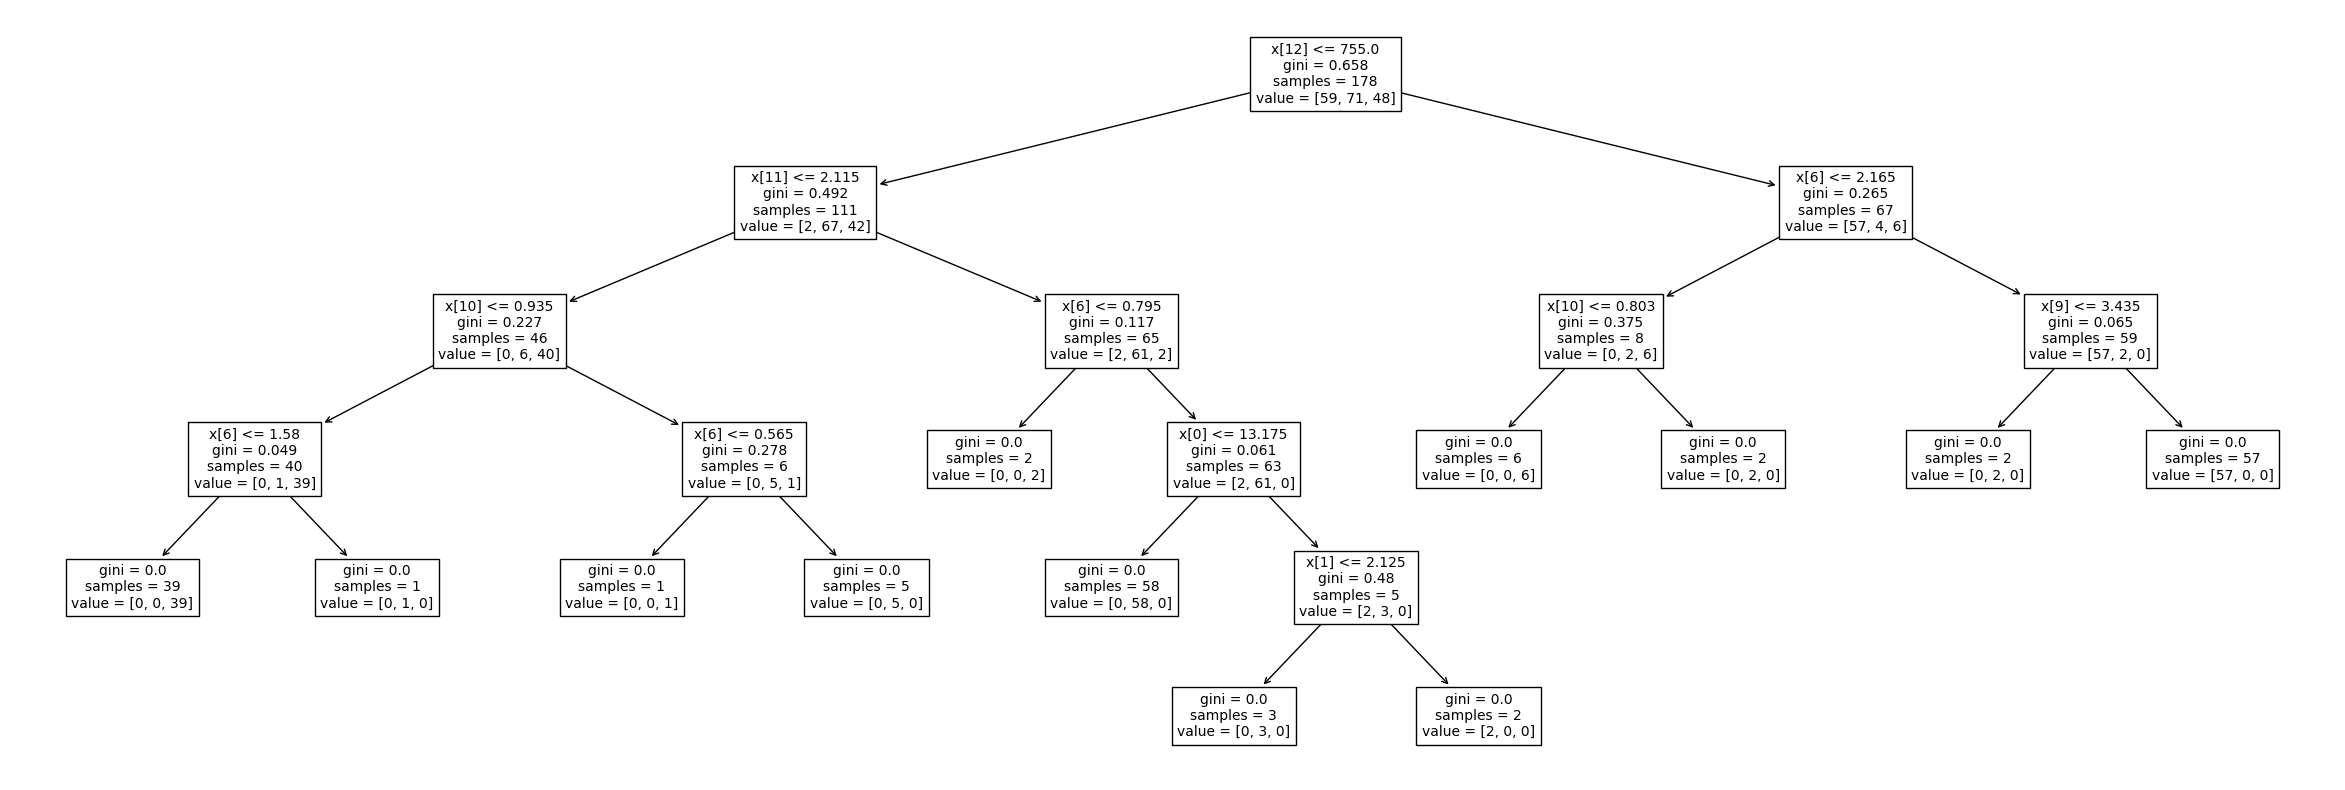

In [32]:
switch(data)